## 05 — Sliding-window check, corrected to match XDec-CHI's STAR Methods

### Aim
* `01_artifact_diagnosis.ipynb` Section 5 adapted XDec-CHI's sliding-window method into a diagnostic for whether `Profile_7`'s broad, non-specific reference correlation is an NNLS estimation artifact or a real minority compartment, but its mechanic diverged from the paper's own procedure in three ways (see Methods note below). This notebook redoes that check with the paper's actual mechanic, kept separate from `01_artifact_diagnosis.ipynb` to avoid editing a notebook that's open live elsewhere.
* Question is unchanged from Section 5: does `Profile_7`'s reference-correlation signature sharpen (real compartment) or stay flat (artifact) as the window composition shifts?

### Input
* The baseline n=150/k=9 Stage 1 fit (`data/deconvolution/xdec/stage1_with_refs_k9_n150`) — fixed `proportions.tsv` and `cell_type_profiles.tsv`, not refit per window
* `KRT19` bulk TPM expression (`data/processed/TCGA-PAAD_TPM_raw.tsv`) as the ranking gene of interest (a ductal/epithelial marker; appeared among `Profile_7`'s own top-20 zero-floor genes in notebook 01 Section 1)
* 111 cached Stage-2-only outputs (`data/deconvolution/xdec/sliding_window_profile7_fixed_stage1/stage2_w*`), one per overlapping 40-sample window (step 1, samples ranked ascending by `KRT19` TPM)
* Peng et al. single-cell reference (`refs.tsv`, `ref_metadata.tsv`) and the shared Stage-0 probe list

### Output
* A single window × (patient, cell-type) correlation heatmap for `Profile_7` across all 111 windows (one figure, the same shape of result as the paper's single sliding-window plot)
* A summary trend plot of breadth (both at 10-cell-type and 270-column granularity) / reference margin / zero-floor count vs. window `KRT19` enrichment

### Methods note — what changed from Section 5
XDec-CHI's STAR Methods ("Sliding window deconvolution and cell type specific correlations"): *"Stage 1 was performed on the entire cohort to estimate cell type proportions. Samples were then ordered by bulk expression of a gene of interest. Stage 2 was then performed on the groups of 40 samples... The window was then moved by one sample... repeated until every sample had been deconvoluted."*

| | Section 5 (notebook 01) | This notebook |
|---|---|---|
| Stage 1 | refit independently per window (new NMF init, new profile identities, needed post-hoc profile-matching) | **fixed** — one baseline fit reused everywhere |
| Ranking variable | a profile's own fitted proportion | **bulk expression of a gene of interest** (`KRT19`) |
| Window step | 6 big, mostly-non-overlapping windows | **step 1**, 111 overlapping windows |

With Stage 1 fixed, `Profile_7` always means the same thing, so there is no profile-matching step and no identity-drift confound — only Stage 2 (a cheap regression given fixed proportions) differs window to window.

### Steps
* Rebuild the patient × cell-type pseudobulk reference (same layout as notebook 01 Figure 2 / Section 2)
* For each of the 111 cached windows, correlate `Profile_7`'s window-specific Stage 2 mean expression against the pseudobulk reference over the shared Stage-0 probes
* Assemble one heatmap (window × reference column) and one scalar summary table (breadth, margin, zero-floor count vs. enrichment)

### Result
* **Breadth is perfectly saturated and completely flat**: `Profile_7` correlates at r>0.3 with **all 10/10 reference cell types and all 270/270 individual patient × cell-type reference columns, in every single one of the 111 windows**, from the lowest-`KRT19` window (mean TPM 889) to the highest (mean TPM 4893). There is no variation to even compute a Spearman trend (`breadth` is a constant — correlation undefined). The heatmap is visually uniform blue across its entire 111×270 extent, with no column block (cell type) or row band (enrichment level) standing out.
* **Specificity (top-minus-second reference margin) stays tiny throughout** — 0.0002 to 0.021 (i.e., the single best-matching reference column is at most ~2% more correlated than the second-best) — and is not increasing with enrichment: Spearman *r* = **-0.31** against window mean `KRT19` TPM, i.e. if anything weakly *less* specific at higher enrichment.
* The zero-floor boundary-gene count does increase somewhat with enrichment (*r* = 0.58, range 132–235), but this plausibly reflects a mechanical Stage-2 regression-weight effect (more total signal attributed to `Profile_7` as the window shifts toward KRT19-high samples) rather than sharpening biological specificity, since it is not accompanied by any corresponding change in breadth or margin.

### Conclusion
* With the confound from Sections 5–6's independent Stage 1 refits removed, this is now an unambiguous result in the same single-plot form as the paper's own method: `Profile_7`'s signature is **completely invariant to window composition** — not just non-sharpening, but saturated at the maximum possible breadth everywhere. This is strong, direct evidence **consistent with `Profile_7` being an NNLS estimation artifact** (a component absorbing broadly-expressed residual signal) **rather than a real minority cell-type compartment**, which should have shown at least some narrowing of its reference match as the window was enriched for a plausible marker of it.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Find progress/ from either the notebook directory or progress/ itself.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)
XDEC_DIR = "data/deconvolution/xdec"
BASELINE_STAGE1_DIR = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150")
WINDOWS_DIR = os.path.join(XDEC_DIR, "sliding_window_profile7_fixed_stage1")
CORR_THRESHOLD = 0.3
RANKING_GENE = "KRT19"

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)


def read_genes(path):
    genes = Path(path).read_text().splitlines()
    return list(dict.fromkeys(g.strip() for g in genes if g.strip()))

### Pseudobulk reference and window manifest

Rebuild the patient × cell-type pseudobulk reference (same layout as notebook 01/04), and load the window manifest (sample composition and mean `KRT19` TPM per window) written alongside the cached Stage 2 outputs.

In [2]:
refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
probe_list = read_genes(os.path.join(XDEC_DIR, "stage0", "selected_probes.txt"))

if not refs.index.is_unique or not refs.columns.is_unique or not ref_meta.index.is_unique:
    raise ValueError("Duplicate reference or metadata labels")
ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]
if ref_cell_types.isna().any():
    raise ValueError("Missing cell types in reference metadata")

cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
if set(cell_type_order) != set(ref_cell_types.unique()):
    raise ValueError("Cell-type order must cover the reference metadata")
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))

patients = pd.Series(refs.columns, index=refs.columns).str.split("_").str[0]
if patients.eq("").any() or not refs.columns.str.contains("_").all():
    raise ValueError("Expected patient-prefixed reference cell IDs")
group_key = patients + " | " + ref_cell_types.astype(str)
reference_means = refs.T.groupby(group_key, sort=True).mean().T
pb_cell_types = pd.Series({c: c.split(" | ", 1)[1] for c in reference_means.columns})
pb_order = pb_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
reference_means = reference_means.loc[:, pb_order]

manifest = pd.read_csv(os.path.join(WINDOWS_DIR, "window_manifest.tsv"), sep="\t")
if len(manifest) != 111:
    raise ValueError(f"Expected 111 windows in the manifest; found {len(manifest)}")
manifest = manifest.sort_values("start").reset_index(drop=True)
print(f"Pseudobulk reference: {reference_means.shape[0]} genes × {reference_means.shape[1]} (patient, cell-type) columns")
print(f"Window manifest: {len(manifest)} windows, mean {RANKING_GENE} TPM "
      f"{manifest['mean_KRT19_tpm'].min():.0f}–{manifest['mean_KRT19_tpm'].max():.0f}")

Pseudobulk reference: 17004 genes × 270 (patient, cell-type) columns
Window manifest: 111 windows, mean KRT19 TPM 889–4893


### Per-window Profile_7 reference correlation

For each of the 111 windows, correlate `Profile_7`'s window-specific Stage 2 mean expression against every patient × cell-type reference column, over the shared Stage-0 probes. Store the full 270-column correlation vector per window (for the heatmap) plus the usual scalar summaries (breadth, top/second reference *r*, margin, zero-floor count) from Sections 1 and 5 of notebook 01.

In [3]:
TARGET_PROFILE = "Profile_7"

window_corr_rows = {}
summary_rows = []

for _, row in manifest.iterrows():
    tag = row["tag"]
    s2_dir = os.path.join(WINDOWS_DIR, f"stage2_{tag}")
    means_path = os.path.join(s2_dir, "stage2_means.tsv")
    if not os.path.exists(means_path):
        raise FileNotFoundError(f"Missing cached Stage 2 output for window {tag}: {means_path}")
    w_means = pd.read_csv(means_path, sep="\t", index_col=0)

    genes = [g for g in probe_list if g in refs.index and g in w_means.index]
    if len(genes) < 10:
        raise ValueError(f"{tag}: insufficient shared genes for correlation")
    combined = pd.concat([reference_means.loc[genes], w_means.loc[genes, [TARGET_PROFILE]]], axis=1)
    correlations = combined.corr(method="spearman")[TARGET_PROFILE].drop(TARGET_PROFILE)
    if not np.isfinite(correlations.to_numpy()).all():
        raise ValueError(f"{tag}: undefined correlations; check for constant expression vectors")
    window_corr_rows[tag] = correlations.loc[pb_order]

    ranked_ref = correlations.sort_values(ascending=False)
    celltype_means = correlations.groupby(pb_cell_types.loc[pb_order]).mean()
    target_means = w_means[TARGET_PROFILE]
    zf_counts = {
        other: int(((w_means[other] == 0) & (target_means > target_means.quantile(0.99))).sum())
        for other in w_means.columns if other != TARGET_PROFILE
    }
    summary_rows.append({
        "window": tag, "start": int(row["start"]), "mean_KRT19_tpm": float(row["mean_KRT19_tpm"]),
        "breadth_columns_r_gt_0.3": int((correlations > CORR_THRESHOLD).sum()),
        "breadth_celltypes_r_gt_0.3": int((celltype_means > CORR_THRESHOLD).sum()),
        "top_reference_r": float(ranked_ref.iloc[0]),
        "second_reference_r": float(ranked_ref.iloc[1]),
        "reference_margin": float(ranked_ref.iloc[0] - ranked_ref.iloc[1]),
        "max_n_zero_floor_genes": max(zf_counts.values()),
    })

window_corr_matrix = pd.DataFrame(window_corr_rows).T.loc[manifest["tag"]]
summary_df = pd.DataFrame(summary_rows).sort_values("start").reset_index(drop=True)
summary_df.describe()

,start,mean_KRT19_tpm,breadth_columns_r_gt_0.3,breadth_celltypes_r_gt_0.3,top_reference_r,second_reference_r,reference_margin,max_n_zero_floor_genes
count,111.000000,111.000000,111.0,111.0,111.000000,111.000000,111.000000,111.000000
mean,55.000000,2539.706653,270.0,10.0,0.709384,0.703086,0.006297,168.909910
std,32.186954,1045.162960,0.0,0.0,0.023095,0.023118,0.004968,20.585763
min,0.000000,888.703560,270.0,10.0,0.664209,0.656349,0.000189,132.000000
25%,27.500000,1690.904477,270.0,10.0,0.694527,0.685487,0.002377,153.000000
50%,55.000000,2398.025415,270.0,10.0,0.706484,0.701650,0.004665,165.000000
75%,82.500000,3306.890931,270.0,10.0,0.724353,0.717326,0.009583,185.000000
max,110.000000,4893.233967,270.0,10.0,0.782341,0.771628,0.020836,235.000000


### One heatmap: 111 windows × (patient, cell-type) reference

Rows are the 111 overlapping windows, ordered by increasing mean `KRT19` enrichment (bottom = lowest, top = highest); columns are the same 270 patient × cell-type reference means used throughout, sorted by cell type. If `Profile_7` is a real, sharpening ductal/epithelial compartment, the pancreatic-ductal-cell column block (second from the left) should darken moving up the rows; if it is an estimation artifact, the whole heatmap should look uniformly diffuse regardless of row.

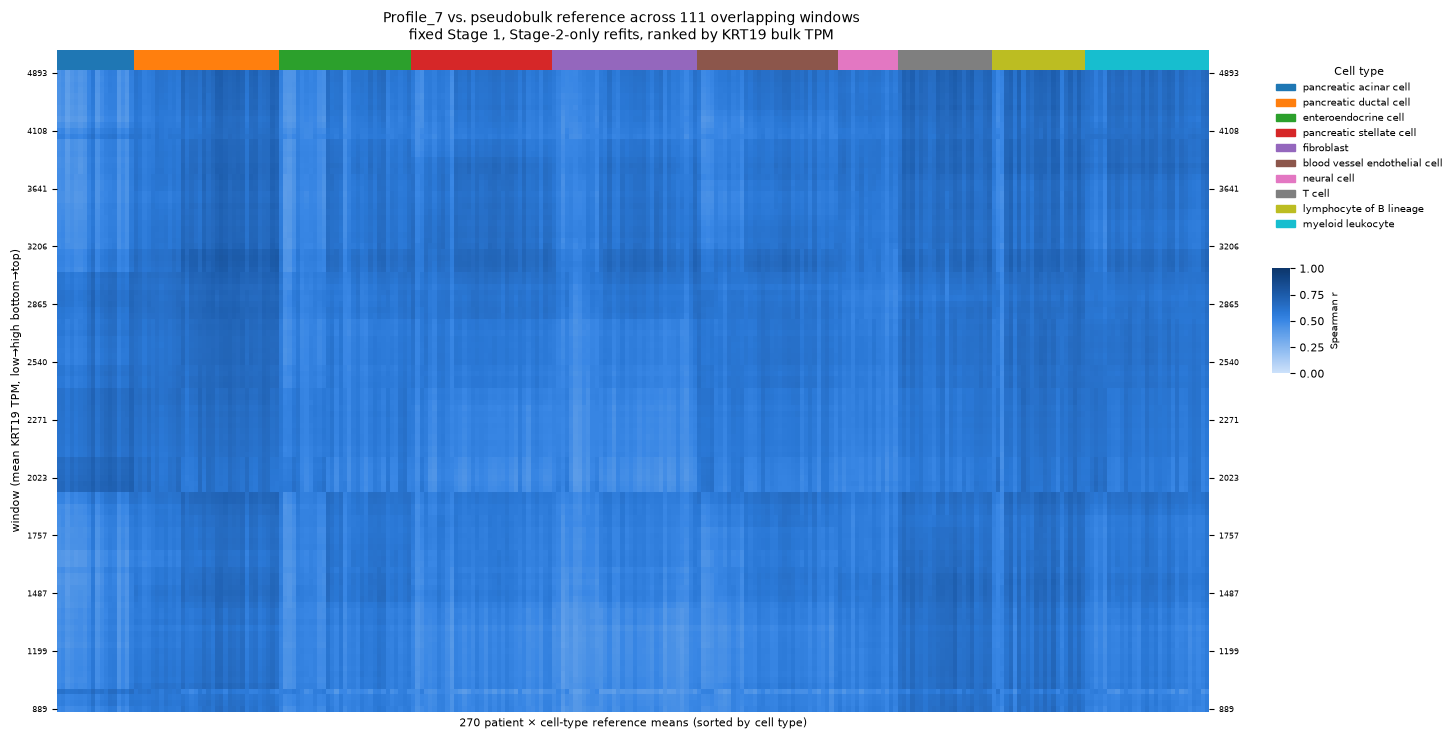

saved paper_duplication/figures/fig_sliding_window_fixed_stage1_profile_7_vs_reference.png


In [4]:
heatmap_matrix = window_corr_matrix.iloc[::-1]  # lowest enrichment at bottom, highest at top
row_tick_step = 10
row_tick_idx = list(range(0, len(heatmap_matrix), row_tick_step))
row_labels = [f"{manifest.set_index('tag').loc[t, 'mean_KRT19_tpm']:.0f}" for t in heatmap_matrix.index]

grid = sns.clustermap(
    heatmap_matrix, row_cluster=False, col_cluster=False,
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=False, figsize=(12, 7),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.02, 0.02),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order)} patient × cell-type reference means (sorted by cell type)")
grid.ax_heatmap.set_ylabel(f"window (mean {RANKING_GENE} TPM, low→high bottom→top)")
grid.ax_heatmap.set_yticks([i + 0.5 for i in row_tick_idx])
grid.ax_heatmap.set_yticklabels([row_labels[i] for i in row_tick_idx], rotation=0, fontsize=6)
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", left=True, labelleft=True)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle(f"{TARGET_PROFILE} vs. pseudobulk reference across 111 overlapping windows\n"
                   f"fixed Stage 1, Stage-2-only refits, ranked by {RANKING_GENE} bulk TPM", y=1.02, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

figures_dir = Path("paper_duplication/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
heatmap_path = figures_dir / f"fig_sliding_window_fixed_stage1_{TARGET_PROFILE.lower()}_vs_reference.png"
grid.savefig(heatmap_path, dpi=200, bbox_inches="tight")
window_corr_matrix.to_csv(heatmap_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(grid.fig)
print("saved", heatmap_path)

### Summary trend across all 111 windows

Same three scalar summaries as Section 5 of notebook 01 (breadth, reference margin, zero-floor count), now as a continuous trend over 111 step-1 windows instead of 6 discrete points.

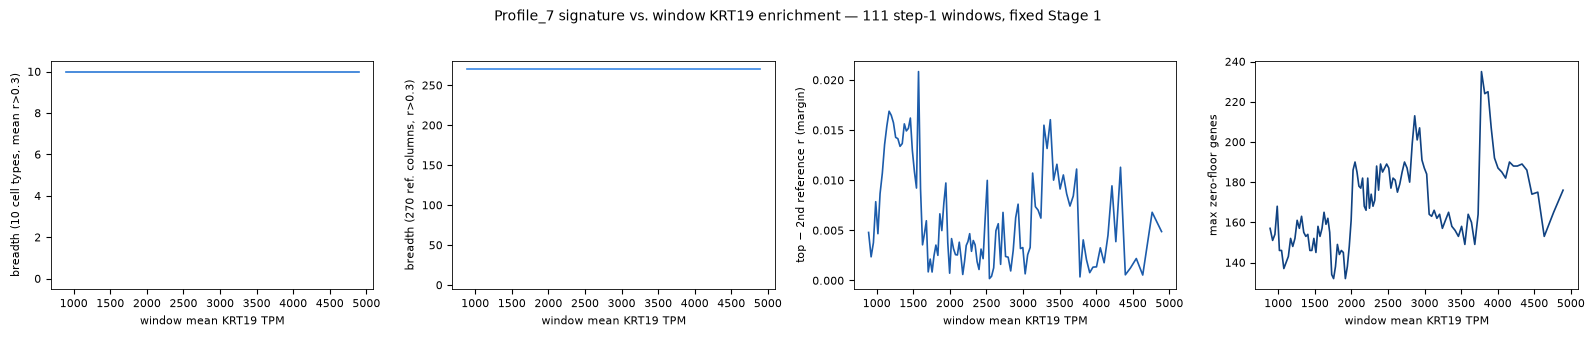

saved paper_duplication/figures/fig_sliding_window_fixed_stage1_profile_7_trend.png

Spearman correlation of each metric with window mean KRT19 TPM:
  breadth_celltypes_r_gt_0.3: r=nan, range=[10, 10]
  breadth_columns_r_gt_0.3: r=nan, range=[270, 270]
  reference_margin: r=-0.30556335556335557, range=[0.00018926775291816522, 0.020836053808481192]
  max_n_zero_floor_genes: r=0.5750682194702852, range=[132, 235]


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/pandas/core/nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/pandas/core/nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
x = summary_df["mean_KRT19_tpm"]

axes[0].plot(x, summary_df["breadth_celltypes_r_gt_0.3"], "-", color="#2a78d6", linewidth=1.2)
axes[0].set_ylabel("breadth (10 cell types, mean r>0.3)")
axes[0].set_ylim(-0.5, 10.5)

axes[1].plot(x, summary_df["breadth_columns_r_gt_0.3"], "-", color="#3987e5", linewidth=1.2)
axes[1].set_ylabel("breadth (270 ref. columns, r>0.3)")
axes[1].set_ylim(-5, 280)

axes[2].plot(x, summary_df["reference_margin"], "-", color="#1c5cab", linewidth=1.2)
axes[2].set_ylabel("top − 2nd reference r (margin)")

axes[3].plot(x, summary_df["max_n_zero_floor_genes"], "-", color="#104281", linewidth=1.2)
axes[3].set_ylabel("max zero-floor genes")

for ax in axes:
    ax.set_xlabel(f"window mean {RANKING_GENE} TPM")

fig.suptitle(f"{TARGET_PROFILE} signature vs. window {RANKING_GENE} enrichment — 111 step-1 windows, fixed Stage 1",
             y=1.03, fontsize=10)
fig.tight_layout()
trend_path = figures_dir / f"fig_sliding_window_fixed_stage1_{TARGET_PROFILE.lower()}_trend.png"
fig.savefig(trend_path, dpi=200, bbox_inches="tight")
summary_df.to_csv(trend_path.with_suffix(".tsv"), sep="\t", index=False)
plt.show()
plt.close(fig)
print("saved", trend_path)

print(f"\nSpearman correlation of each metric with window mean {RANKING_GENE} TPM:")
for col in ["breadth_celltypes_r_gt_0.3", "breadth_columns_r_gt_0.3", "reference_margin", "max_n_zero_floor_genes"]:
    r = summary_df[col].corr(summary_df["mean_KRT19_tpm"], method="spearman")
    print(f"  {col}: r={r}, range=[{summary_df[col].min()}, {summary_df[col].max()}]")